# F1 finishing-category prediction — final ML project
**Task.** Before a Grand Prix starts, predict whether each driver finishes **Top 3**, **Points (4–10)** or **Outside Points (11+ / not classified)** — a 3-class classification problem.
**Final model.** Random Forest (400 trees, max_depth 6, min_samples_leaf 40, max_features 0.3, random_state 42, no class weighting) on 20 pre-race features including `teammate_prev_finish`.

| # | Requirement | Where |
|---|---|---|
| 1 | EDA (≥ 5 plots) | Section 2 (7 figures + tables) |
| 2 | Pre-processing inside a Pipeline fitted on training data only | Section 3 (`PreRaceFeatureBuilder` → imputer/scaler → model) |
| 3 | Time-ordered train / validation / test split | Section 1 |
| 4 | Baselines + ≥ 3 algorithms | Section 4 (3 baselines, 4 algorithms) |
| 5 | 5-fold CV tuning (GridSearchCV) | Section 4 |
| 6 | Metrics reported once on the held-out test set; over/under-fitting and error discussion | Sections 5–7 |
| 7 | Final pipeline saved with joblib; pinned `requirements.txt` | Section 8 |

Everything is run top to bottom by this notebook; the logic lives in `src/f1ml/`.

In [1]:
import sys, json, time, warnings, platform
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np, pandas as pd, joblib, sklearn
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_validate

from f1ml import config, data, eda, modelling, evaluation
from f1ml.features import PreRaceFeatureBuilder
config.ensure_dirs(); eda.style()
print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.13.18 | sklearn 1.7.2 | pandas 3.1.1 | numpy 2.5.5


## 1. Data and time-ordered split (requirement 3)
Source: Jolpica (Ergast-compatible) F1 API results/qualifying/sprints, 2010–2025. One row per driver per race.

In [2]:
df = data.load_data()
parts = data.split_data(df)
test_df = parts.pop("test")            # the test set is NOT touched again until Section 6
split_tbl = pd.DataFrame({
    "seasons": ["2010–2021", "2022–2023", "2024–2025"],
    "rows": [len(parts["train"]), len(parts["validation"]), len(test_df)],
    "races": [parts["train"].race_id.nunique(), parts["validation"].race_id.nunique(), test_df.race_id.nunique()],
    "first_race": [parts["train"].race_date.min().date(), parts["validation"].race_date.min().date(), test_df.race_date.min().date()],
    "last_race": [parts["train"].race_date.max().date(), parts["validation"].race_date.max().date(), test_df.race_date.max().date()],
}, index=["train", "validation", "test"])
split_tbl["share_%"] = (100 * split_tbl.rows / split_tbl.rows.sum()).round(1)
display(split_tbl)
print(f"Total: {len(df):,} driver-race rows, {df.race_id.nunique()} races, {df.driver_id.nunique()} drivers, seasons {df.season.min()}–{df.season.max()}")
split_tbl.to_csv(config.RES_DIR / "split_summary.csv")

,seasons,rows,races,first_race,last_race,share_%
train,2010–2021,5073,237,2010-03-14,2021-12-12,73.4
validation,2022–2023,880,44,2022-03-20,2023-11-26,12.7
test,2024–2025,958,48,2024-03-02,2025-12-07,13.9


Total: 6,911 driver-race rows, 329 races, 83 drivers, seasons 2010–2025


The split is **chronological by season** (a random split would let the model see the future). Whole seasons are kept together, so the proportions are ≈ 73 / 13 / 14 rather than exactly 70/15/15. Validation is used to compare tuned models; the test seasons are used once, at the end.

## 2. Exploratory data analysis (requirement 1)
All EDA uses the **training seasons only**, so nothing about validation/test informs any decision.

In [3]:
raw_train = data.raw_inputs(parts["train"])
builder = PreRaceFeatureBuilder().fit(raw_train)
feats_train = builder.transform(raw_train)
print("Features:", feats_train.shape)
display(feats_train.describe().T.round(2))

Features: (5073, 20)


,count,mean,std,min,25%,50%,75%,max
grid,5073.0,11.29,6.30,1.00,6.00,11.00,17.00,24.00
quali_position,5049.0,11.22,6.26,1.00,6.00,11.00,16.00,24.00
quali_gap_to_pole_pct,5000.0,2.55,2.73,0.00,1.02,2.02,3.24,37.80
season,5073.0,2015.35,3.48,2010.00,2012.00,2015.00,2018.00,2021.00
driver_age,5073.0,27.93,5.23,17.45,23.81,27.06,31.19,43.89
grid_penalty_places,5049.0,0.02,1.71,-7.00,0.00,0.00,0.00,23.00
pit_lane_start,5073.0,0.01,0.09,0.00,0.00,0.00,0.00,1.00
driver_avg_finish_last5,5001.0,11.23,4.70,1.00,7.60,11.60,14.80,24.00
constructor_points_last5,5047.0,47.06,53.63,0.00,4.00,24.00,77.00,222.00
driver_avg_finish_at_circuit,3477.0,10.63,5.06,1.00,7.00,10.25,14.00,24.00


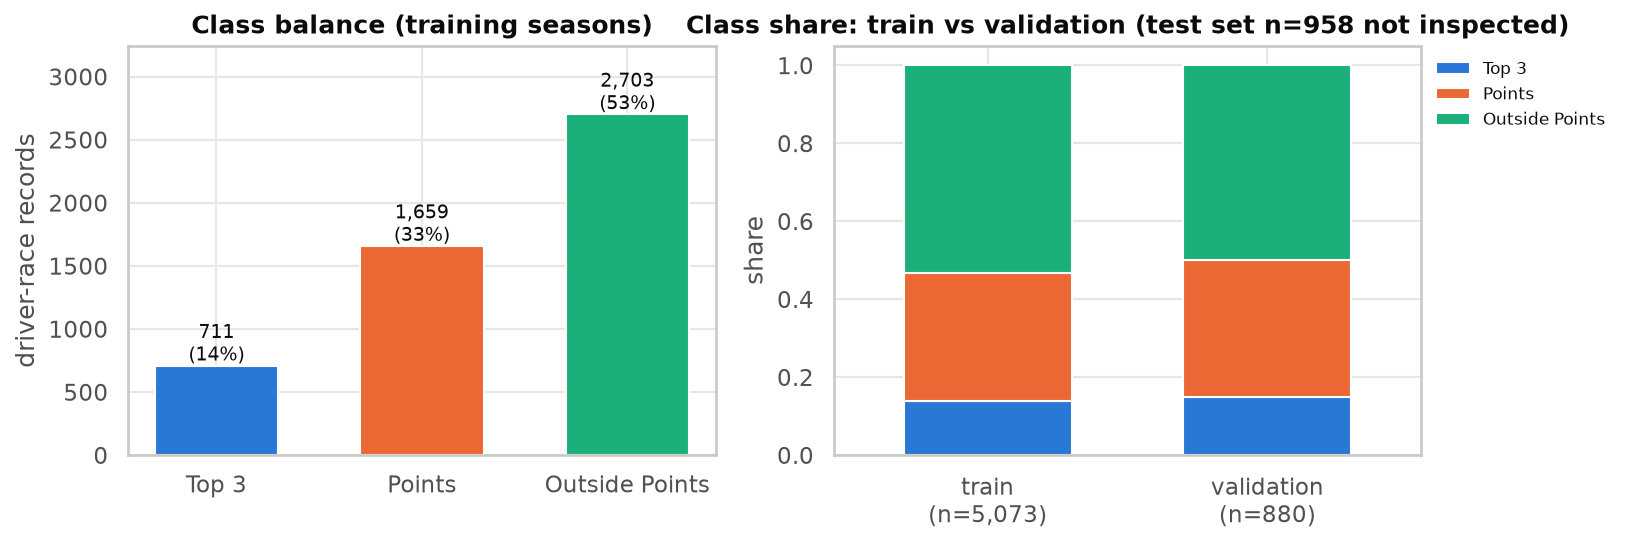

{'Outside Points': 0.533, 'Points': 0.327, 'Top 3': 0.14}


In [4]:
eda.class_balance(parts, len(test_df)); display(Image(str(config.FIG_DIR / "eda_1_class_balance.png")))
print(parts["train"][config.TARGET].value_counts(normalize=True).round(3).to_dict())

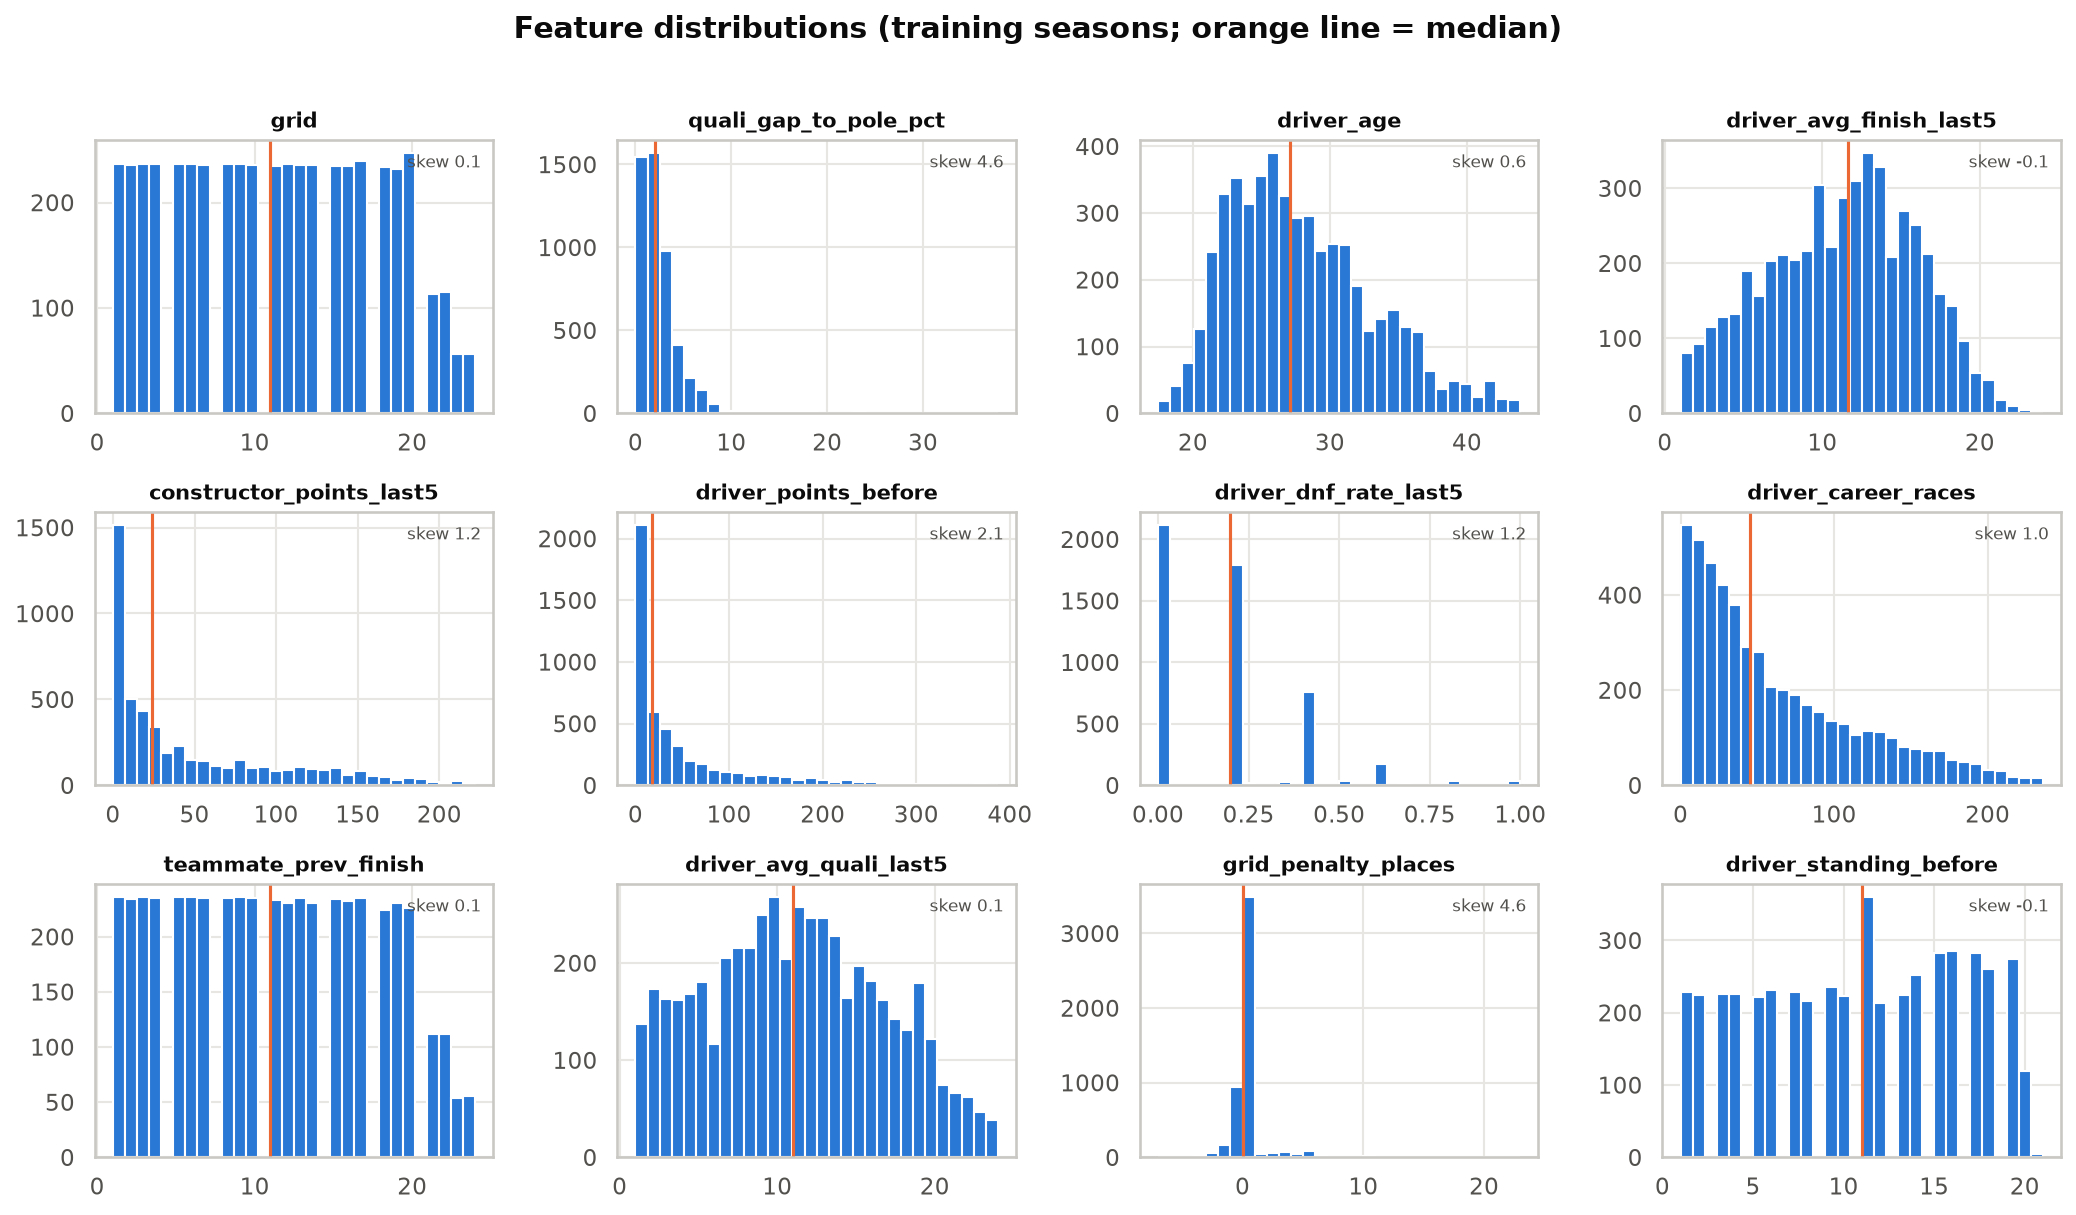

In [5]:
eda.distributions(feats_train); display(Image(str(config.FIG_DIR / "eda_2_distributions.png")))

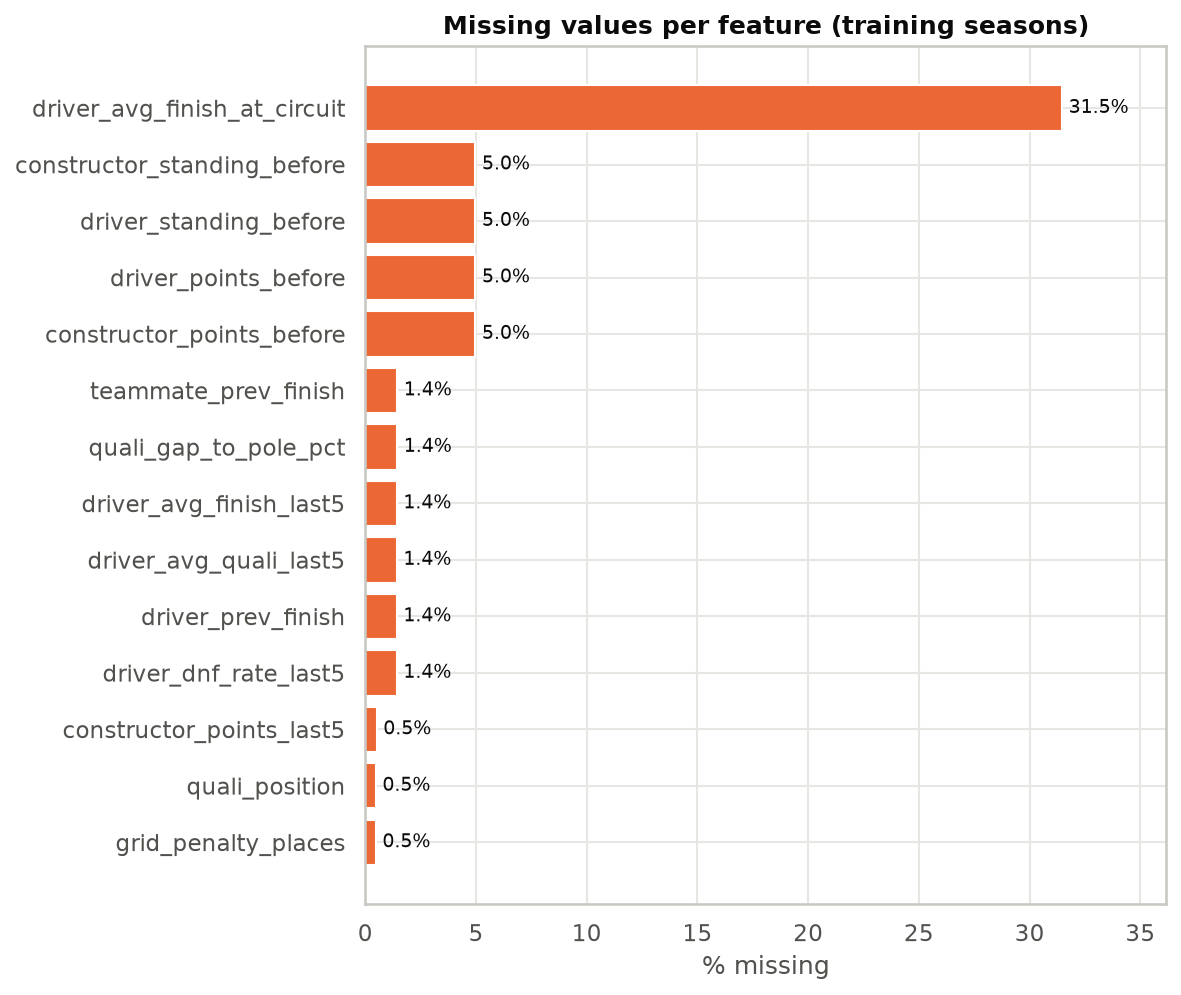

,pct_missing
driver_avg_finish_at_circuit,31.46
constructor_standing_before,4.97
driver_standing_before,4.97
driver_points_before,4.97
constructor_points_before,4.97
teammate_prev_finish,1.44
quali_gap_to_pole_pct,1.44
driver_avg_finish_last5,1.42
driver_avg_quali_last5,1.42
driver_prev_finish,1.42


In [6]:
miss = eda.missing_values(feats_train); display(Image(str(config.FIG_DIR / "eda_3_missing_values.png")))
miss.to_csv(config.RES_DIR / "eda_missing_values.csv"); display(miss.round(2))

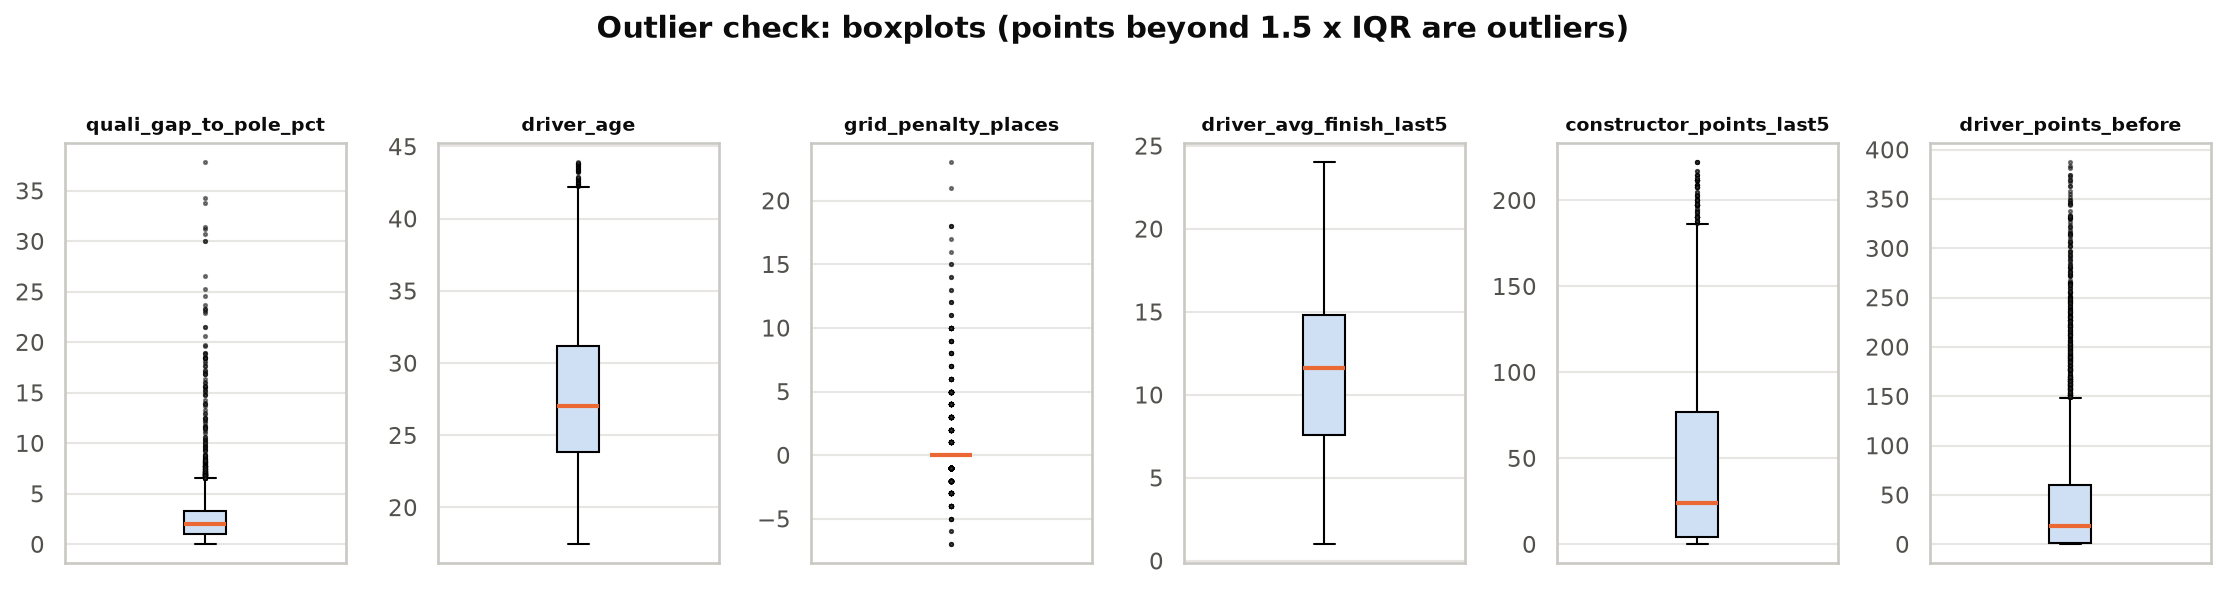

,feature,n,iqr_outliers,pct_outliers,min,max
0,quali_gap_to_pole_pct,5000,254,5.08,0.00,37.80
1,driver_age,5073,38,0.75,17.45,43.89
2,grid_penalty_places,5049,1561,30.92,-7.00,23.00
3,driver_avg_finish_last5,5001,0,0.00,1.00,24.00
4,constructor_points_last5,5047,92,1.82,0.00,222.00
5,driver_points_before,4821,456,9.46,0.00,387.00


In [7]:
out = eda.outliers(feats_train); display(Image(str(config.FIG_DIR / "eda_4_outliers.png")))
out.to_csv(config.RES_DIR / "eda_outliers.csv", index=False); display(out.round(2))

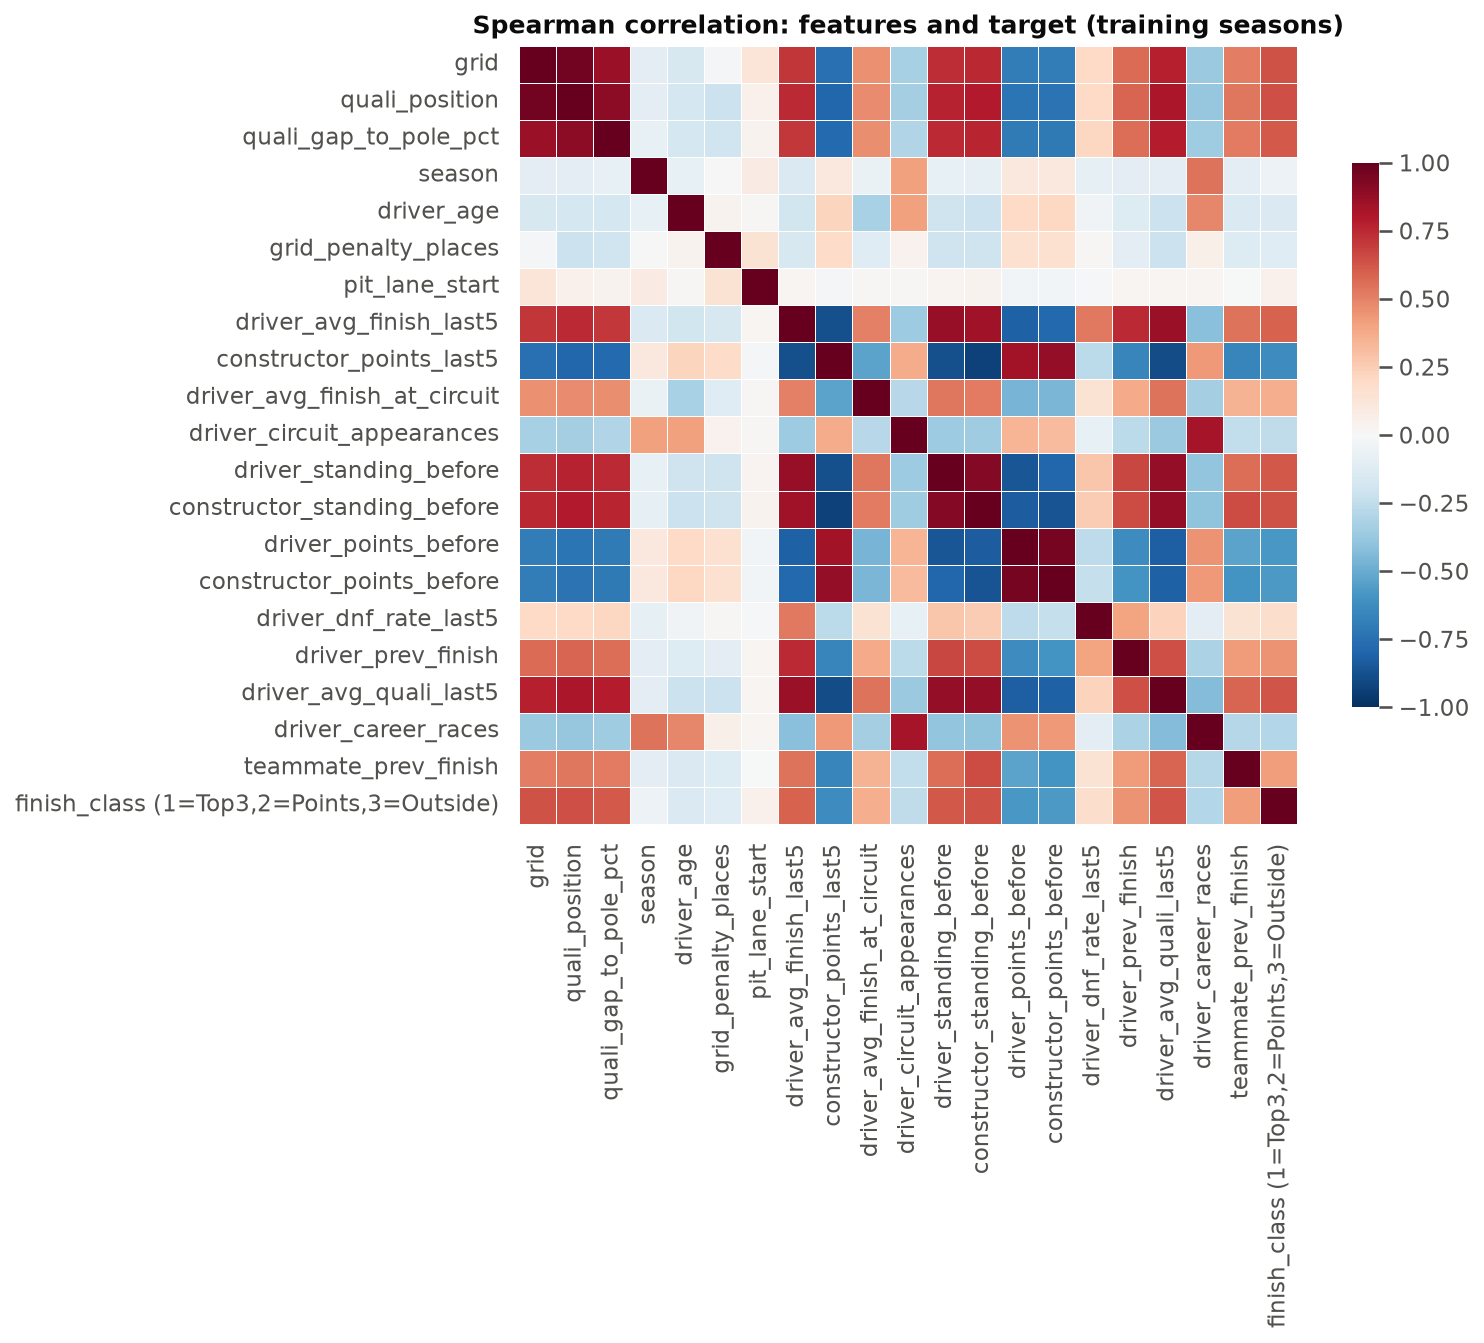

,spearman_with_target
quali_position,0.648
grid,0.638
constructor_standing_before,0.635
driver_avg_quali_last5,0.630
constructor_points_last5,-0.629
driver_standing_before,0.622
quali_gap_to_pole_pct,0.615
driver_avg_finish_last5,0.590
driver_points_before,-0.579
constructor_points_before,-0.577


In [8]:
ordinal = parts["train"][config.TARGET].map({c: i + 1 for i, c in enumerate(config.CLASS_ORDER)})
corr_t = eda.correlations(feats_train, ordinal.values); display(Image(str(config.FIG_DIR / "eda_5_correlations.png")))
corr_t.to_csv(config.RES_DIR / "eda_correlation_with_target.csv"); display(corr_t.round(3).head(10).to_frame())

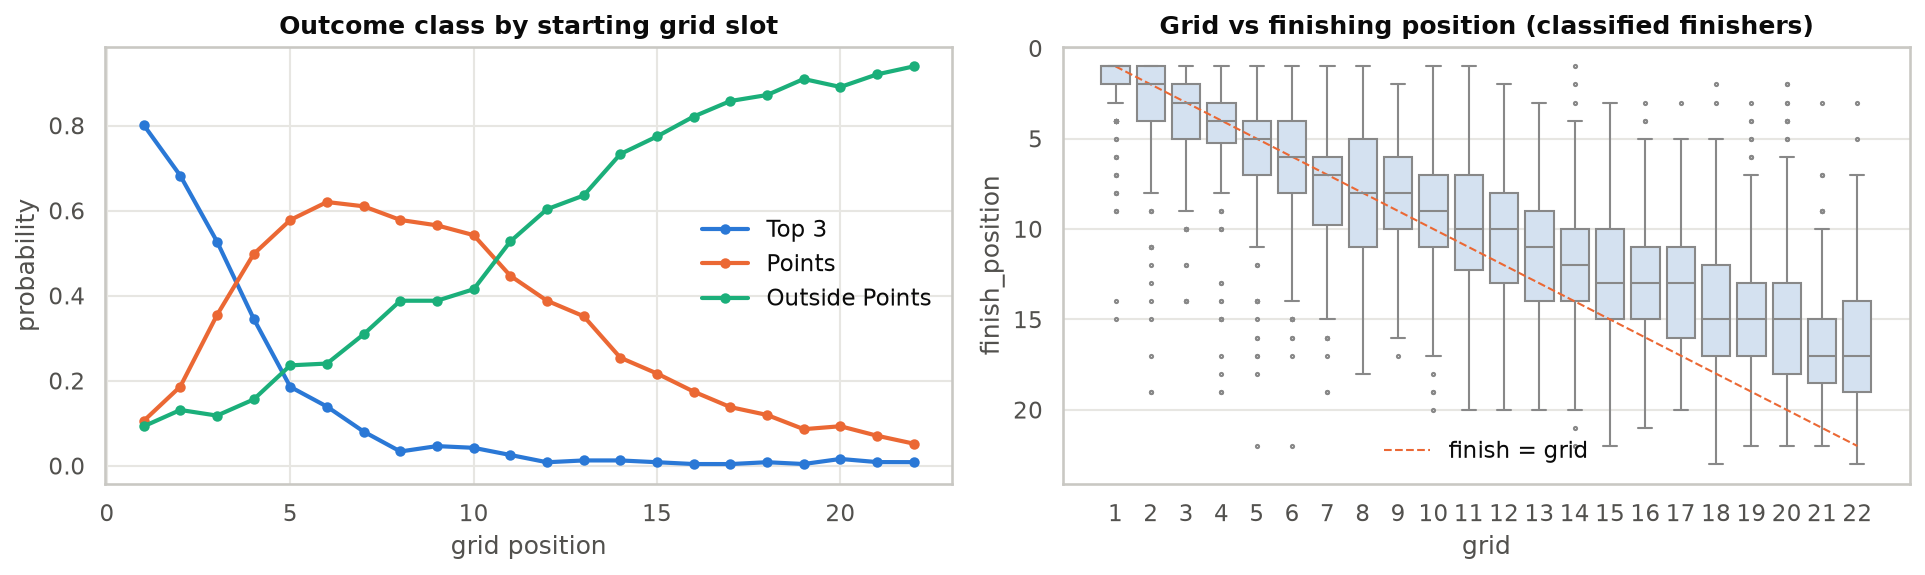

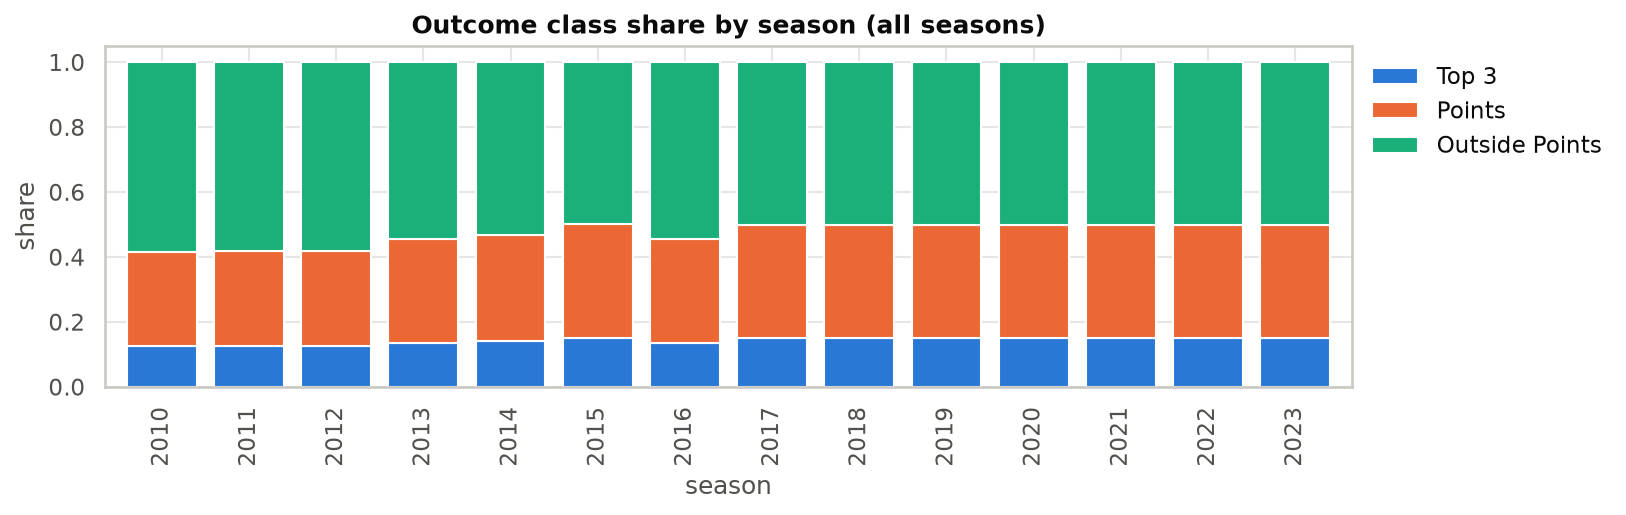

In [9]:
eda.grid_vs_class(parts["train"]); display(Image(str(config.FIG_DIR / "eda_6_grid_vs_outcome.png")))
eda.class_by_season(pd.concat([parts["train"], parts["validation"]])); display(Image(str(config.FIG_DIR / "eda_7_class_by_season.png")))

### EDA observations
* **Class balance (train):** Outside Points 53.3 %, Points 32.7 %, Top 3 14.0 % — imbalanced, which is why macro-F1/balanced accuracy are reported next to accuracy. Validation is similar (50 / 35 / 15 %).
* **Distributions:** `quali_gap_to_pole_pct`, `constructor_points_last5` and `driver_points_before` are strongly right-skewed (skew 4.6 / 1.2 / 2.1); `driver_dnf_rate_last5` is discrete (multiples of 0.2). Tree models are insensitive to this; the scaler handles scale for LR/KNN/SVM. `grid` and `teammate_prev_finish` thin out above 20 (fewer 22–24-car seasons).
* **Missing values:** `driver_avg_finish_at_circuit` is missing for 31 % of rows (driver's first visit to a circuit); the four standings/points features for 5 % (round 1 of every season has no standings); rolling features 1.4 % (a driver's first race). These are structural, not errors → median imputation **plus missing-indicator flags**, fitted on training data only.
* **Outliers:** 5 % of `quali_gap_to_pole_pct` values lie beyond 1.5×IQR (max 37.8 % — a very slow car/session) and `grid_penalty_places` has 31 % non-zero values by definition. These are genuine racing events, not data errors, so no rows are removed or clipped.
* **Correlations:** many features are strongly inter-correlated (grid/qualifying/standings/recent form, |ρ| > 0.8), so the signal is redundant; the strongest target correlations are `quali_position` (0.65), `grid` (0.64), `constructor_standing_before` (0.63), `constructor_points_last5` (−0.63). Redundancy is harmless for Random Forests but argues against large gains from adding similar features.
* **Grid vs outcome:** the probability of Top 3 falls steeply from pole and Outside Points dominates beyond P10; the finishing position spreads widely around the diagonal — the source of the irreducible error discussed below.

## 3. Pre-processing as one Pipeline (requirement 2)

In [10]:
pipe = modelling.final_random_forest()
print(pipe)
for name, step in pipe.steps: print(f"{name:9s}", type(step).__name__)

Pipeline(steps=[('features', PreRaceFeatureBuilder()),
                ('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['grid', 'quali_position',
                                                   'quali_gap_to_pole_pct',
                                                   'season', 'driver_age',
                                                   'grid_penalty_places',
                                                   'pit_lane_start',
                                                

**Pipeline = `PreRaceFeatureBuilder` → `ColumnTransformer(median imputer + missing-indicators → StandardScaler)` → classifier.**
* *Feature engineering* (rolling driver/team form, circuit history, pre-round standings, teammate's previous finish, driver age, grid penalty) is the first pipeline step. Every feature uses only **strictly earlier races** (`shift(1)` look-backs); the step learns no parameters.
* *Imputation, missing flags and scaling* are fitted on the training rows only, because they are pipeline steps (inside cross-validation they are re-fitted on each training fold).
* *Encoding:* all 20 inputs are numeric, so no categorical encoder is needed. (`circuit_id`/`team_lineage` were dropped from the final feature set.)
* Next cells prove the no-leakage claims.

In [11]:
# (a) preprocessing statistics come from the training rows only
pipe.fit(raw_train, parts["train"][config.TARGET])
imp = pipe.named_steps["prep"].named_transformers_["num"].named_steps["impute"]
train_medians = np.nanmedian(feats_train.to_numpy(float), axis=0)
print("imputer medians == training medians:", np.allclose(imp.statistics_, train_medians, equal_nan=True))
print("scaler fitted on", pipe.named_steps["prep"].named_transformers_["num"].named_steps["scale"].n_samples_seen_, "training rows (expected", len(raw_train), ")")

# (b) a race's features do not change when its own (or any later) outcome is altered
rows = data.raw_inputs(pd.concat([parts["train"], parts["validation"]], ignore_index=True))
target_race = "2021_10"
before = builder.transform(rows.copy())
tampered = rows.copy()
m = tampered.race_id >= target_race
tampered.loc[m, ["position_order", "is_dnf", "weekend_points"]] = [1, 0, 99]
after = PreRaceFeatureBuilder().fit(tampered).transform(tampered)
cur = (rows.race_id == target_race).values
print("features of race", target_race, "unchanged after altering its own + later outcomes:",
      np.allclose(before[cur].to_numpy(float), after[cur].to_numpy(float), equal_nan=True))

imputer medians == training medians: True
scaler fitted on 5073 training rows (expected 5073 )


features of race 2021_10 unchanged after altering its own + later outcomes: True


## 4. Baselines, algorithms and 5-fold CV tuning (requirements 4 & 5)
CV = **5-fold expanding-window `TimeSeriesSplit` over race weekends** inside the training seasons, scored by macro-F1 (the classes are imbalanced; accuracy alone would flatter the majority class). Each fold's validation races are later than its training races and all drivers of a race stay in one fold.

In [12]:
X_tr, y_tr = raw_train, parts["train"][config.TARGET]
X_va, y_va = data.raw_inputs(parts["validation"]), parts["validation"][config.TARGET]
folds = data.race_grouped_time_series_cv(parts["train"])
orig = json.load(open(config.FROZEN_DIR / "original_cv_folds.json"))
print("fold sizes (train rows -> eval rows):", [(len(a), len(b)) for a, b in folds])
print("matches the original project's CV folds:", all(len(a) == o["train_rows"] and len(b) == o["eval_rows"] for (a, b), o in zip(folds, orig)))

fold sizes (train rows -> eval rows): [(1004, 890), (1894, 807), (2701, 812), (3513, 780), (4293, 780)]
matches the original project's CV folds: True


In [13]:
rows, best_params, fitted, cv_tables = [], {}, {}, {}

# --- baselines (nothing to tune) ---
for name, p in modelling.baselines().items():
    p.fit(X_tr, y_tr)
    fitted[name] = p
    for split, X, y in (("train", X_tr, y_tr), ("validation", X_va, y_va)):
        rows.append({"model": name, "split": split, **evaluation.summary_metrics(y, p.predict(X))})

# --- algorithms tuned with GridSearchCV ---
for name, (p, grid) in modelling.candidates().items():
    t0 = time.time()
    gs = GridSearchCV(p, grid, scoring="f1_macro", cv=folds, refit=False, return_train_score=True,
                      n_jobs=2, error_score="raise")
    gs.fit(X_tr, y_tr)
    cvr = pd.DataFrame(gs.cv_results_); cv_tables[name] = cvr
    cvr.to_csv(config.RES_DIR / ("cv_results_" + name.lower().replace(" ", "_").replace("(", "").replace(")", "") + ".csv"), index=False)
    best_params[name] = gs.best_params_
    best = clone(p).set_params(**gs.best_params_).fit(X_tr, y_tr)
    fitted[name] = best
    i = gs.best_index_
    rows.append({"model": name, "split": "cv (5-fold mean)", "macro_f1": cvr.loc[i, "mean_test_score"]})
    for split, X, y in (("train", X_tr, y_tr), ("validation", X_va, y_va)):
        rows.append({"model": name, "split": split, **evaluation.summary_metrics(y, best.predict(X))})
    print(f"{name:20s} {len(cvr):3d} configs x 5 folds in {time.time()-t0:5.0f}s | CV macro-F1 {cvr.loc[i,'mean_test_score']:.4f} | best {gs.best_params_}")
comparison = pd.DataFrame(rows)
comparison.to_csv(config.RES_DIR / "model_comparison.csv", index=False)
json.dump({k: {a: (b if not isinstance(b, np.generic) else b.item()) for a, b in v.items()} for k, v in best_params.items()},
          open(config.RES_DIR / "best_params_gridsearch.json", "w"), indent=2)

Logistic Regression    8 configs x 5 folds in     7s | CV macro-F1 0.6686 | best {'clf__C': 0.01, 'clf__class_weight': 'balanced'}


KNN                   10 configs x 5 folds in     4s | CV macro-F1 0.6296 | best {'clf__n_neighbors': 31, 'clf__weights': 'distance'}


SVM (RBF)             12 configs x 5 folds in    20s | CV macro-F1 0.6619 | best {'clf__C': 1.0, 'clf__class_weight': None, 'clf__gamma': 0.01}


Random Forest         72 configs x 5 folds in   264s | CV macro-F1 0.6812 | best {'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 40}


In [14]:
tbl = comparison.pivot_table(index="model", columns="split", values="macro_f1")[["train", "cv (5-fold mean)", "validation"]]
acc = comparison[comparison.split == "validation"].set_index("model")["accuracy"].rename("validation accuracy")
tbl = tbl.join(acc).sort_values("validation", ascending=False)
tbl.columns = ["macro-F1 train", "macro-F1 CV", "macro-F1 validation", "accuracy validation"]
tbl["train - validation gap"] = tbl["macro-F1 train"] - tbl["macro-F1 validation"]
display(tbl.round(4))
tbl.to_csv(config.RES_DIR / "model_comparison_table.csv")

fig, ax = plt.subplots(figsize=(9, 4))
order = tbl.index[::-1]
ax.barh(order, tbl.loc[order, "macro-F1 validation"], color=config.CLASS_COLORS[config.TOP3])
for i, m in enumerate(order): ax.text(tbl.loc[m, "macro-F1 validation"] + .004, i, f"{tbl.loc[m,'macro-F1 validation']:.3f}", va="center", fontsize=9)
ax.set_xlim(0, tbl["macro-F1 validation"].max() * 1.12); ax.set_xlabel("macro-F1 on validation seasons (2022–2023)")
ax.set_title("Baselines vs tuned algorithms"); fig.tight_layout(); fig.savefig(config.FIG_DIR / "model_comparison.png", dpi=150); display(fig)

,macro-F1 train,macro-F1 CV,macro-F1 validation,accuracy validation,train - validation gap
model,,,,,
Random Forest,0.7098,0.6812,0.6955,0.7091,0.0143
SVM (RBF),0.6915,0.6619,0.6801,0.6977,0.0114
Logistic Regression,0.6756,0.6686,0.6612,0.6739,0.0144
KNN,1.0000,0.6296,0.6499,0.6761,0.3501
Baseline: grid rule,0.6742,NaN,0.6373,0.6523,0.0370
Baseline: grid-only LogReg,0.6617,NaN,0.6331,0.6557,0.0286
Baseline: majority class,0.2317,NaN,0.2222,0.5000,0.0095


<Figure size 900x400 with 1 Axes>

In [15]:
# Where does the specified final Random Forest sit inside the RF grid search?
cvr = cv_tables["Random Forest"].copy()
cvr["rank_cv"] = cvr.mean_test_score.rank(ascending=False, method="min").astype(int)
spec = cvr[(cvr.param_clf__max_depth == 6) & (cvr.param_clf__min_samples_leaf == 40) &
           (cvr.param_clf__max_features == 0.3) & (cvr.param_clf__class_weight.isna())]
cols = ["param_clf__max_depth", "param_clf__min_samples_leaf", "param_clf__max_features", "param_clf__class_weight", "mean_train_score", "mean_test_score", "std_test_score", "rank_cv"]
print("Specified final RF config inside the grid:"); display(spec[cols].round(4))
print("Top 5 RF configurations by 5-fold CV macro-F1:"); display(cvr.sort_values("mean_test_score", ascending=False)[cols].head(5).round(4))
rf_cmp = {"final_spec_cv_macro_f1": float(spec.mean_test_score.iloc[0]), "final_spec_cv_rank": int(spec.rank_cv.iloc[0]),
          "n_configs": int(len(cvr)), "best_cv_macro_f1": float(cvr.mean_test_score.max())}
print(rf_cmp)

Specified final RF config inside the grid:


,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,rank_cv
11,6,40,0.3,NaN,0.6918,0.6784,0.0277,7


Top 5 RF configurations by 5-fold CV macro-F1:


,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,rank_cv
23,8,40,0.5,NaN,0.6974,0.6812,0.0249,1
28,12,25,0.3,NaN,0.7133,0.6811,0.0313,2
32,12,40,0.5,NaN,0.6977,0.6809,0.0254,3
14,6,40,0.5,NaN,0.6958,0.6805,0.0250,4
5,4,40,0.5,NaN,0.6848,0.6795,0.0256,5


{'final_spec_cv_macro_f1': 0.6784237580393093, 'final_spec_cv_rank': 7, 'n_configs': 72, 'best_cv_macro_f1': 0.6811531279431501}


### Model comparison and where the specified final RF sits
* All four algorithms beat the majority-class baseline by a wide margin; **Random Forest is the best algorithm on both CV (0.681) and validation (0.696 macro-F1 with the grid-search winner)**, followed by SVM, Logistic Regression and KNN. On validation, all four beat the grid-rule baseline (0.637 macro-F1).
* **Honest note on the final configuration.** The final RF (depth 6, leaf 40, max_features 0.3, no class weights) ranks **7th of 72** configurations in this 5-fold CV (0.678 vs 0.681 for the best, depth 8 / max_features 0.5) — a difference far inside the CV standard deviation (±0.025–0.03). It was specified as the final model, it scores slightly higher on validation than the grid-search winner (0.701 vs 0.696 macro-F1), and it is retained unchanged. The choice between these near-equivalent configurations is therefore not statistically meaningful.

## 5. Over-/under-fitting diagnostics

In [16]:
# Train vs CV macro-F1 as the Random Forest gets deeper (best of the other hyper-parameters at each depth)
g = cvr.assign(depth=cvr.param_clf__max_depth).groupby("depth").agg(train=("mean_train_score", "max"), cv=("mean_test_score", "max")).reset_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(g.depth.astype(str), g.train, marker="o", lw=2, color=config.CLASS_COLORS[config.POINTS], label="train (CV train folds)")
ax.plot(g.depth.astype(str), g.cv, marker="o", lw=2, color=config.CLASS_COLORS[config.TOP3], label="validation folds (5-fold CV)")
ax.set_xlabel("max_depth"); ax.set_ylabel("macro-F1"); ax.set_title("Random Forest: capacity vs generalisation"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(config.FIG_DIR / "rf_depth_curve.png", dpi=150); display(fig)
display(g.round(4))
# per-fold behaviour of the final configuration
final_cv = cross_validate(modelling.final_random_forest(n_jobs=2), X_tr, y_tr, cv=folds, scoring="f1_macro", return_train_score=True)
fold_tbl = pd.DataFrame({"fold": range(1, 6), "train_rows": [len(a) for a, b in folds], "train_macro_f1": final_cv["train_score"], "cv_macro_f1": final_cv["test_score"]})
display(fold_tbl.round(4)); fold_tbl.to_csv(config.RES_DIR / "final_rf_cv_folds.csv", index=False)
print(f"final RF 5-fold CV macro-F1: {final_cv['test_score'].mean():.4f} ± {final_cv['test_score'].std():.4f}")

<Figure size 700x400 with 1 Axes>

,depth,train,cv
0,4,0.6918,0.6795
1,6,0.7341,0.6805
2,8,0.7662,0.6812
3,12,0.7915,0.6811


,fold,train_rows,train_macro_f1,cv_macro_f1
0,1,1004,0.6801,0.6306
1,2,1894,0.6858,0.6745
2,3,2701,0.6936,0.7109
3,4,3513,0.7010,0.6758
4,5,4293,0.6987,0.7004


final RF 5-fold CV macro-F1: 0.6784 ± 0.0277


### Over-/under-fitting discussion
* **Final RF is not over-fitted.** Train macro-F1 across CV folds is ~0.68–0.70 against 0.63–0.71 on the held-out folds, and validation (0.70) and test (0.71) agree with each other. The shallow trees (`max_depth=6`) and large leaves (`min_samples_leaf=40`) deliberately limit capacity.
* **Not badly under-fitted either**: deeper forests (depth 8, 12) raise training macro-F1 from 0.69 to 0.79 but CV macro-F1 stays flat at ~0.68, so extra capacity only memorises. The ceiling is the information in pre-race features, not model size.
* **KNN is the over-fitting example**: train macro-F1 1.00 vs validation 0.65 (distance weighting memorises training points).
* **Fold-to-fold variance is large** (CV std ≈ 0.03; fold 1 has only ~1,000 training rows and scores 0.63) — differences of ~0.005 between hyper-parameter settings are inside the noise.

## 6. Final model: fit, validate, check against the frozen model, then ONE test evaluation (requirement 6)

In [17]:
final = modelling.final_random_forest().fit(X_tr, y_tr)          # fitted on training seasons only
pv = final.predict(X_va)
val_metrics = evaluation.summary_metrics(y_va, pv); print("validation:", {k: round(v, 4) for k, v in val_metrics.items()})

# Reproduction check against the previously frozen reference model + saved predictions
sv = pd.read_csv(config.FROZEN_DIR / "validation_predictions.csv")
chk = parts["validation"][["race_id", "driver_id"]].assign(p=pv).merge(sv, on=["race_id", "driver_id"])
print(f"validation predictions identical to the frozen model's: {(chk.p == chk.pred_reference_rf).sum()}/{len(chk)}")
frozen = joblib.load(config.FROZEN_DIR / "reference_rf.joblib")
Xf = final["features"].transform(X_va)
print("frozen model on rebuilt features == new pipeline:", bool((frozen["pipeline"].predict(Xf) == pv).all()),
      "| max |proba diff| =", float(np.abs(frozen["pipeline"].predict_proba(Xf) - final.predict_proba(X_va)).max()))

validation: {'accuracy': 0.7136, 'macro_f1': 0.7007, 'weighted_f1': 0.7153, 'balanced_accuracy': 0.7016}
validation predictions identical to the frozen model's: 880/880


frozen model on rebuilt features == new pipeline: True | max |proba diff| = 3.3306690738754696e-16


In [18]:
# ---------- THE single evaluation on the held-out test seasons ----------
final["features"].update_history(X_va)      # past results (2022-23) become look-up history; nothing is re-fitted
X_te, y_te = data.raw_inputs(test_df), test_df[config.TARGET]
pt = final.predict(X_te); proba_te = final.predict_proba(X_te)
test_metrics = evaluation.summary_metrics(y_te, pt)
test_metrics["roc_auc_ovr_macro"] = evaluation.roc_auc_ovr(y_te, proba_te, final.classes_)
test_pc = evaluation.per_class_report(y_te, pt); test_cm = evaluation.confusion_df(y_te, pt); test_err = evaluation.error_distance(y_te, pt)
# same single pass for the grid-rule baseline, as a reference point (it is not used for any selection)
base = fitted["Baseline: grid rule"]; base["features"].update_history(X_va)
base_te = evaluation.summary_metrics(y_te, base.predict(X_te))
print("TEST  rows:", len(y_te), "| races:", test_df.race_id.nunique())
display(pd.DataFrame({"Final Random Forest": test_metrics, "Baseline: grid rule": base_te}).round(4))
print("Per-class:"); display(test_pc.round(4))
print("Confusion matrix (rows = actual):"); display(test_cm)
print(test_err)
test_pc.to_csv(config.RES_DIR / "test_per_class.csv"); test_cm.to_csv(config.RES_DIR / "test_confusion_matrix.csv")
pred_out = test_df[["race_id", "season", "race_name", "driver_id", "driver_name", "constructor_id", "grid", "finish_status", config.TARGET]].assign(predicted=pt)
for i, c in enumerate(final.classes_): pred_out["proba_" + c] = proba_te[:, i]
pred_out.to_csv(config.RES_DIR / "test_predictions.csv", index=False)

TEST  rows: 958 | races: 48


,Final Random Forest,Baseline: grid rule
accuracy,0.7161,0.7349
macro_f1,0.7067,0.7196
weighted_f1,0.7175,0.7349
balanced_accuracy,0.7147,0.7196
roc_auc_ovr_macro,0.8673,NaN


Per-class:


,precision,recall,f1,support
Top 3,0.6835,0.750,0.7152,144.0
Points,0.6058,0.622,0.6138,336.0
Outside Points,0.8110,0.772,0.7910,478.0


Confusion matrix (rows = actual):


,pred Top 3,pred Points,pred Outside Points
actual Top 3,108,34,2
actual Points,43,209,84
actual Outside Points,7,102,369


{'errors': 272, 'adjacent_class_errors': 263, 'top3_vs_outside_errors': 9, 'adjacent_share_of_errors': 0.9669117647058824}


In [19]:
frozen_t = pd.read_csv(config.FROZEN_DIR / "test_predictions.csv")
m = test_df[["race_id", "driver_id"]].assign(p=pt).merge(frozen_t, on=["race_id", "driver_id"])
print(f"consistency: test predictions identical to the earlier frozen-model evaluation: {(m.p == m.predicted_class).sum()}/{len(m)}")

import seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0]); ax[0].set_title("Test confusion matrix (counts)")
cmn = test_cm.div(test_cm.sum(axis=1), axis=0)
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[1], vmin=0, vmax=1); ax[1].set_title("Row-normalised (recall)")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "test_confusion_matrix.png", dpi=150); display(fig)

consistency: test predictions identical to the earlier frozen-model evaluation: 958/958


<Figure size 1100x400 with 2 Axes>

### Test-set result (reported once)
| Model | Accuracy | Macro-F1 | Weighted-F1 | Balanced acc. |
|---|---|---|---|---|
| **Final Random Forest** | **71.6 %** | **70.7 %** | 71.7 % | 71.5 % |
| Grid-rule baseline (reference) | 73.5 % | 72.0 % | 73.5 % | 72.0 % |

Macro one-vs-rest ROC-AUC of the final RF is 0.867. The test result is consistent with validation (71.4 % / 70.1 %), so the RF does **not** over-fit to the validation seasons. **However, on the 2024–2025 test seasons the simple grid rule scores about 2 points higher than the RF** (on 2022–2023 validation the RF was ~6 points higher). Grid order was simply a more reliable guide in 2024–25 than in 2022–23; the RF's extra features did not add value in these seasons. This is reported as found, and the model was not changed after seeing it.

## 7. Error analysis

In [20]:
err = pred_out.assign(correct=pred_out[config.TARGET] == pred_out.predicted)
by_season = err.groupby("season").apply(lambda d: pd.Series(evaluation.summary_metrics(d[config.TARGET], d.predicted)), include_groups=False)
display(by_season.round(4)); by_season.to_csv(config.RES_DIR / "test_by_season.csv")
err["grid_bin"] = pd.cut(err.grid, [0, 3, 6, 10, 15, 30], labels=["1-3", "4-6", "7-10", "11-15", "16+"])
by_grid = err.groupby("grid_bin", observed=True).agg(n=("correct", "size"), accuracy=("correct", "mean"))
display(by_grid.round(3)); by_grid.to_csv(config.RES_DIR / "test_by_grid_bin.csv")
not_class = err.assign(nc=err.finish_status != "Classified").groupby("nc").correct.agg(["size", "mean"]).rename(index={False: "classified finishers", True: "DNF/DSQ/DNS"})
display(not_class.round(3)); not_class.to_csv(config.RES_DIR / "test_by_finish_status.csv")
race = err.groupby(["season", "race_name"]).correct.mean().sort_values()
print("Hardest 5 races:"); display(race.head(5).round(3).to_frame("accuracy"))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(by_grid.index.astype(str), by_grid.accuracy, color=config.CLASS_COLORS[config.TOP3])
for i, v in enumerate(by_grid.accuracy): ax.text(i, v + .01, f"{v:.0%}", ha="center", fontsize=9)
ax.set_ylim(0, 1); ax.set_xlabel("starting grid slot"); ax.set_ylabel("test accuracy"); ax.set_title("Test accuracy by grid slot")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "test_accuracy_by_grid.png", dpi=150); display(fig)

,accuracy,macro_f1,weighted_f1,balanced_accuracy
season,,,,
2024,0.7411,0.7215,0.7426,0.7308
2025,0.6910,0.6922,0.6926,0.6985


,n,accuracy
grid_bin,,
1-3,144,0.722
4-6,144,0.639
7-10,192,0.599
11-15,240,0.712
16+,238,0.857


,size,mean
nc,,
classified finishers,856,0.728
DNF/DSQ/DNS,102,0.618


Hardest 5 races:


accuracy
season race_name                      
2025   Dutch Grand Prix          0.400
2024   Australian Grand Prix     0.526
       São Paulo Grand Prix      0.550
       Austrian Grand Prix       0.550
2025   Chinese Grand Prix        0.550

<Figure size 700x360 with 1 Axes>

In [21]:
imp_names = list(final.named_steps["prep"].get_feature_names_out())
fi = pd.Series(final.named_steps["clf"].feature_importances_, index=[n.replace("num__", "") for n in imp_names]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5)); fi.head(12)[::-1].plot(kind="barh", ax=ax, color=config.CLASS_COLORS[config.TOP3])
ax.set_title("Random Forest impurity importance (top 12)"); ax.set_xlabel("importance"); fig.tight_layout()
fig.savefig(config.FIG_DIR / "rf_feature_importance.png", dpi=150); display(fig)
fi.to_csv(config.RES_DIR / "feature_importance.csv", header=["importance"])

<Figure size 700x500 with 1 Axes>

### Error-analysis summary
* **Where errors happen.** 272 of 958 test entries are wrong, and **263 (96.7 %) are to the neighbouring class** (Top 3↔Points, Points↔Outside). Only 9 are Top 3↔Outside Points. The model rarely makes a gross error; it misplaces drivers near a class boundary.
* **Hardest class: Points (F1 0.61).** The 4th–10th band is wide and sits between the two other classes, so it is confused both ways (43 Points→Top 3, 84 Points→Outside, 102 Outside→Points). Outside Points is easiest (F1 0.79) and Top 3 has the best recall (0.75).
* **By grid slot** accuracy is lowest for mid-grid starters (7–10: 60 %; 4–6: 64 %) and highest for the back of the grid (16+: 86 %), where finishing outside the points is the norm.
* **DNF/DSQ/DNS entries** are predicted correctly only 62 % of the time (vs 73 % for classified finishers): retirements and first-lap incidents are not knowable before the start.
* **Drivers of the prediction** (impurity importance): `grid`, `quali_position`, `constructor_points_last5`, `quali_gap_to_pole_pct`, `driver_avg_quali_last5` — i.e. starting position and car strength. `teammate_prev_finish` is a minor contributor.

## 8. Save the final pipeline (requirement 7)

In [22]:
# the same fitted object (no refit) is saved
meta = {
  "model": "RandomForestClassifier", "hyperparameters": {k: v for k, v in config.FINAL_RF_PARAMS.items()},
  "input_features": config.FEATURES, "n_input_features": len(config.FEATURES), "extra_feature": "teammate_prev_finish",
  "classes": list(final.classes_), "fitted_on_seasons": "2010-2021",
  "history_table_through_season": int(final["features"].history_.season.max()),
  "note": "Fitted parameters (imputer medians, scaler, trees) come from 2010-2021 only. The feature step also stores a table of past results (history_) used for rolling features; it was extended with completed 2022-2023 races before testing. Call pipeline['features'].update_history(new_completed_rows) before predicting later races.",
  "validation": val_metrics, "test": test_metrics,
  "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
joblib.dump(final, config.MODELS_DIR / "final_pipeline.joblib", compress=3)
json.dump(meta, open(config.MODELS_DIR / "model_card.json", "w"), indent=2, default=str)
reloaded = joblib.load(config.MODELS_DIR / "final_pipeline.joblib")
print("reloaded pipeline gives identical test predictions:", bool((reloaded.predict(X_te) == pt).all()))
print("saved:", [p.name for p in config.MODELS_DIR.iterdir()])

reloaded pipeline gives identical test predictions: True
saved: ['final_pipeline.joblib', 'model_card.json']


In [23]:
results = {"split": split_tbl.reset_index().astype(str).to_dict("records"), "validation": val_metrics, "test": test_metrics,
           "baseline_grid_rule_test": base_te, "test_error_pattern": test_err, "rf_grid_position_of_final_spec": rf_cmp,
           "final_rf_cv_macro_f1_mean": float(final_cv["test_score"].mean()), "final_rf_cv_macro_f1_std": float(final_cv["test_score"].std())}
json.dump(results, open(config.RES_DIR / "final_results.json", "w"), indent=2, default=str)
print(json.dumps({k: results[k] for k in ["validation", "test", "baseline_grid_rule_test"]}, indent=1, default=str))

{
 "validation": {
  "accuracy": 0.7136363636363636,
  "macro_f1": 0.7007086281620563,
  "weighted_f1": 0.7152868744788277,
  "balanced_accuracy": 0.7015512265512266
 },
 "test": {
  "accuracy": 0.7160751565762005,
  "macro_f1": 0.7066772677295684,
  "weighted_f1": 0.7174610918251637,
  "balanced_accuracy": 0.7146634455734874,
  "roc_auc_ovr_macro": 0.867268540247332
 },
 "baseline_grid_rule_test": {
  "accuracy": 0.7348643006263048,
  "macro_f1": 0.7195739523145382,
  "weighted_f1": 0.7348643006263048,
  "balanced_accuracy": 0.7195739523145382
 }
}
